In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy.stats import ttest_ind
import seaborn as sns
from math import sqrt
import re
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as mticker
from matplotlib.colors import to_rgb, to_hex

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]
layer_colors = [
    "tab:red",
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:purple",
]
layers = ["L1", "L2/3", "L4", "L5", "L6"]

# Silencing Inhibitory Populations: Power Analysis

In [2]:
net_name = "core"  # change to "core_<variant>" for a model variant
mua_power_all = pd.read_csv(os.path.join(net_name, "metrics", "dg_inh_pop_silencing_power", "dg_all_dirs_mua_power_layer.csv"))

In [3]:
def str2list(str_time):
    str_time = str_time[1:-1]
    array_list = str_time.strip(",").split(", ")
    return np.stack([float(ii) for ii in array_list])

mua_power_all["power"] = mua_power_all["power"].apply(str2list)
mua_power_all["f"] = mua_power_all["f"].apply(str2list)

In [4]:
# get power_df, where the results are averaged across 10 trials
power_df = mua_power_all.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_df.reset_index(inplace=True)
power_df["mean"] = power_df["power"].apply(np.mean, axis=0)
power_df["std"] = power_df["power"].apply(np.std, axis=0)
power_df["se"] = power_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_df["f"] = power_df["f"].apply(np.mean, axis=0)
# power_df.drop(columns=["power"], inplace=True)


In [5]:
# get power_df, where the results are averaged across 10 trials
laminar_power_df = mua_power_all.groupby(["layer", "condition"]).agg(
    {
        "power": list,
        "f": list,
    }
)
laminar_power_df.reset_index(inplace=True)
laminar_power_df["mean"] = laminar_power_df["power"].apply(np.mean, axis=0)
laminar_power_df["std"] = laminar_power_df["power"].apply(np.std, axis=0)
laminar_power_df["f"] = laminar_power_df["f"].apply(np.mean, axis=0)
laminar_power_df.drop(columns=["power"], inplace=True)

mean_power_cond = laminar_power_df.groupby(["condition"]).agg(
    {
        "mean": list,
    }
)
mean_power_cond["max"] = mean_power_cond["mean"].apply(
    lambda row: np.max(np.vstack(np.asanyarray(row)), axis=0)
)
mean_power_cond.rename(columns={"index": "condition"})
mean_power_cond.reset_index(inplace=True)


def get_norm_power(row):
    max_values = mean_power_cond.loc[
        mean_power_cond["condition"].isin([row["condition"]]).values,
        "max",
    ].values[0]
    # print(row["contrast"])
    norm_power = row["mean"] / max_values
    # print(np.max(norm_power))
    return norm_power


laminar_power_df["norm power"] = laminar_power_df.apply(
    lambda row: get_norm_power(row), axis=1
)

In [6]:
color_list = [
    "tab:blue",
    "tab:green",
    "tab:purple",
]


def generate_tones(base_color, num_tones=5, lightness_factor=0.2):
    """Generates lighter tones of a given base color."""
    rgb = to_rgb(base_color)
    tones = []
    for i in range(num_tones):
        # Linearly interpolate towards white (1,1,1)
        # The lightness_factor determines how much lighter each step is
        new_rgb = tuple(min(1.0, c + i * lightness_factor) for c in rgb)
        tones.append(to_hex(new_rgb))
    return tones


all_tones = {}
for color_name in color_list:
    all_tones[color_name] = generate_tones(
        color_name, num_tones=5, lightness_factor=0.1
    )[::-1]

In [7]:
def plot_func(axes, power_df, conditions_list, colors, ii):
    for condition in conditions_list:
        mean_power = power_df.loc[power_df["condition"].isin([condition]), "mean"]
        se_power = power_df.loc[power_df["condition"].isin([condition]), "se"]

        if mean_power.empty:
            continue
        else:
            data = np.vstack(np.asanyarray(mean_power))
            data_se = np.vstack(np.asanyarray(se_power))

        if condition != 'no perturb':
            c = colors[ii]
            ii += 1
        else:
            c = 'k'

        for ax, i in zip(axes[1:], range(1, 6)):
            ax.plot(power_df["f"][0], data[i, :], label=condition, color=c)
            ax.fill_between(
                power_df["f"][0][1:],
                data[i, 1:] - 1.96 * data_se[i, 1:], # 95% confidence interval
                data[i, 1:] + 1.96 * data_se[i, 1:], 
                facecolor=c,
                alpha=0.3,
            )
            ax.set_xlim(0,100)
            if condition == conditions_list[0]:  # Only add text for the first condition to avoid repetition
                ax.text(
                    1,
                    1.25,
                    layers[i],
                    horizontalalignment="right",
                    verticalalignment="top",
                    fontsize=8,
                    alpha=1,
                    transform=ax.transAxes,
                    fontweight="bold",
                ) 
            sns.despine()  # Removes top and right spines by default
            # Position the left spine outward by 10 points
            ax.spines["left"].set_position(("outward", 3))
            # Position the bottom spine outward by 10 points
            ax.spines["bottom"].set_position(("outward", 3))
            
            ax.set_xlim([4, 100])
            ax.set_xticks([4, 20, 40, 60, 80, 100])
            ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
            ax.set_xticks([10, 30, 50, 70, 90], minor=True)
            ax.tick_params(axis='x', which='major', length=5)
            ax.tick_params(axis='x', which='minor', length=3)

            # Format y-axis with scientific notation for large values
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits(
                (-3, 3)
            )  # Use scientific notation for values with >5 digits
            ax.yaxis.set_major_formatter(formatter)
            ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 3))
            ax.tick_params(axis='y', labelsize=8)

    return ii

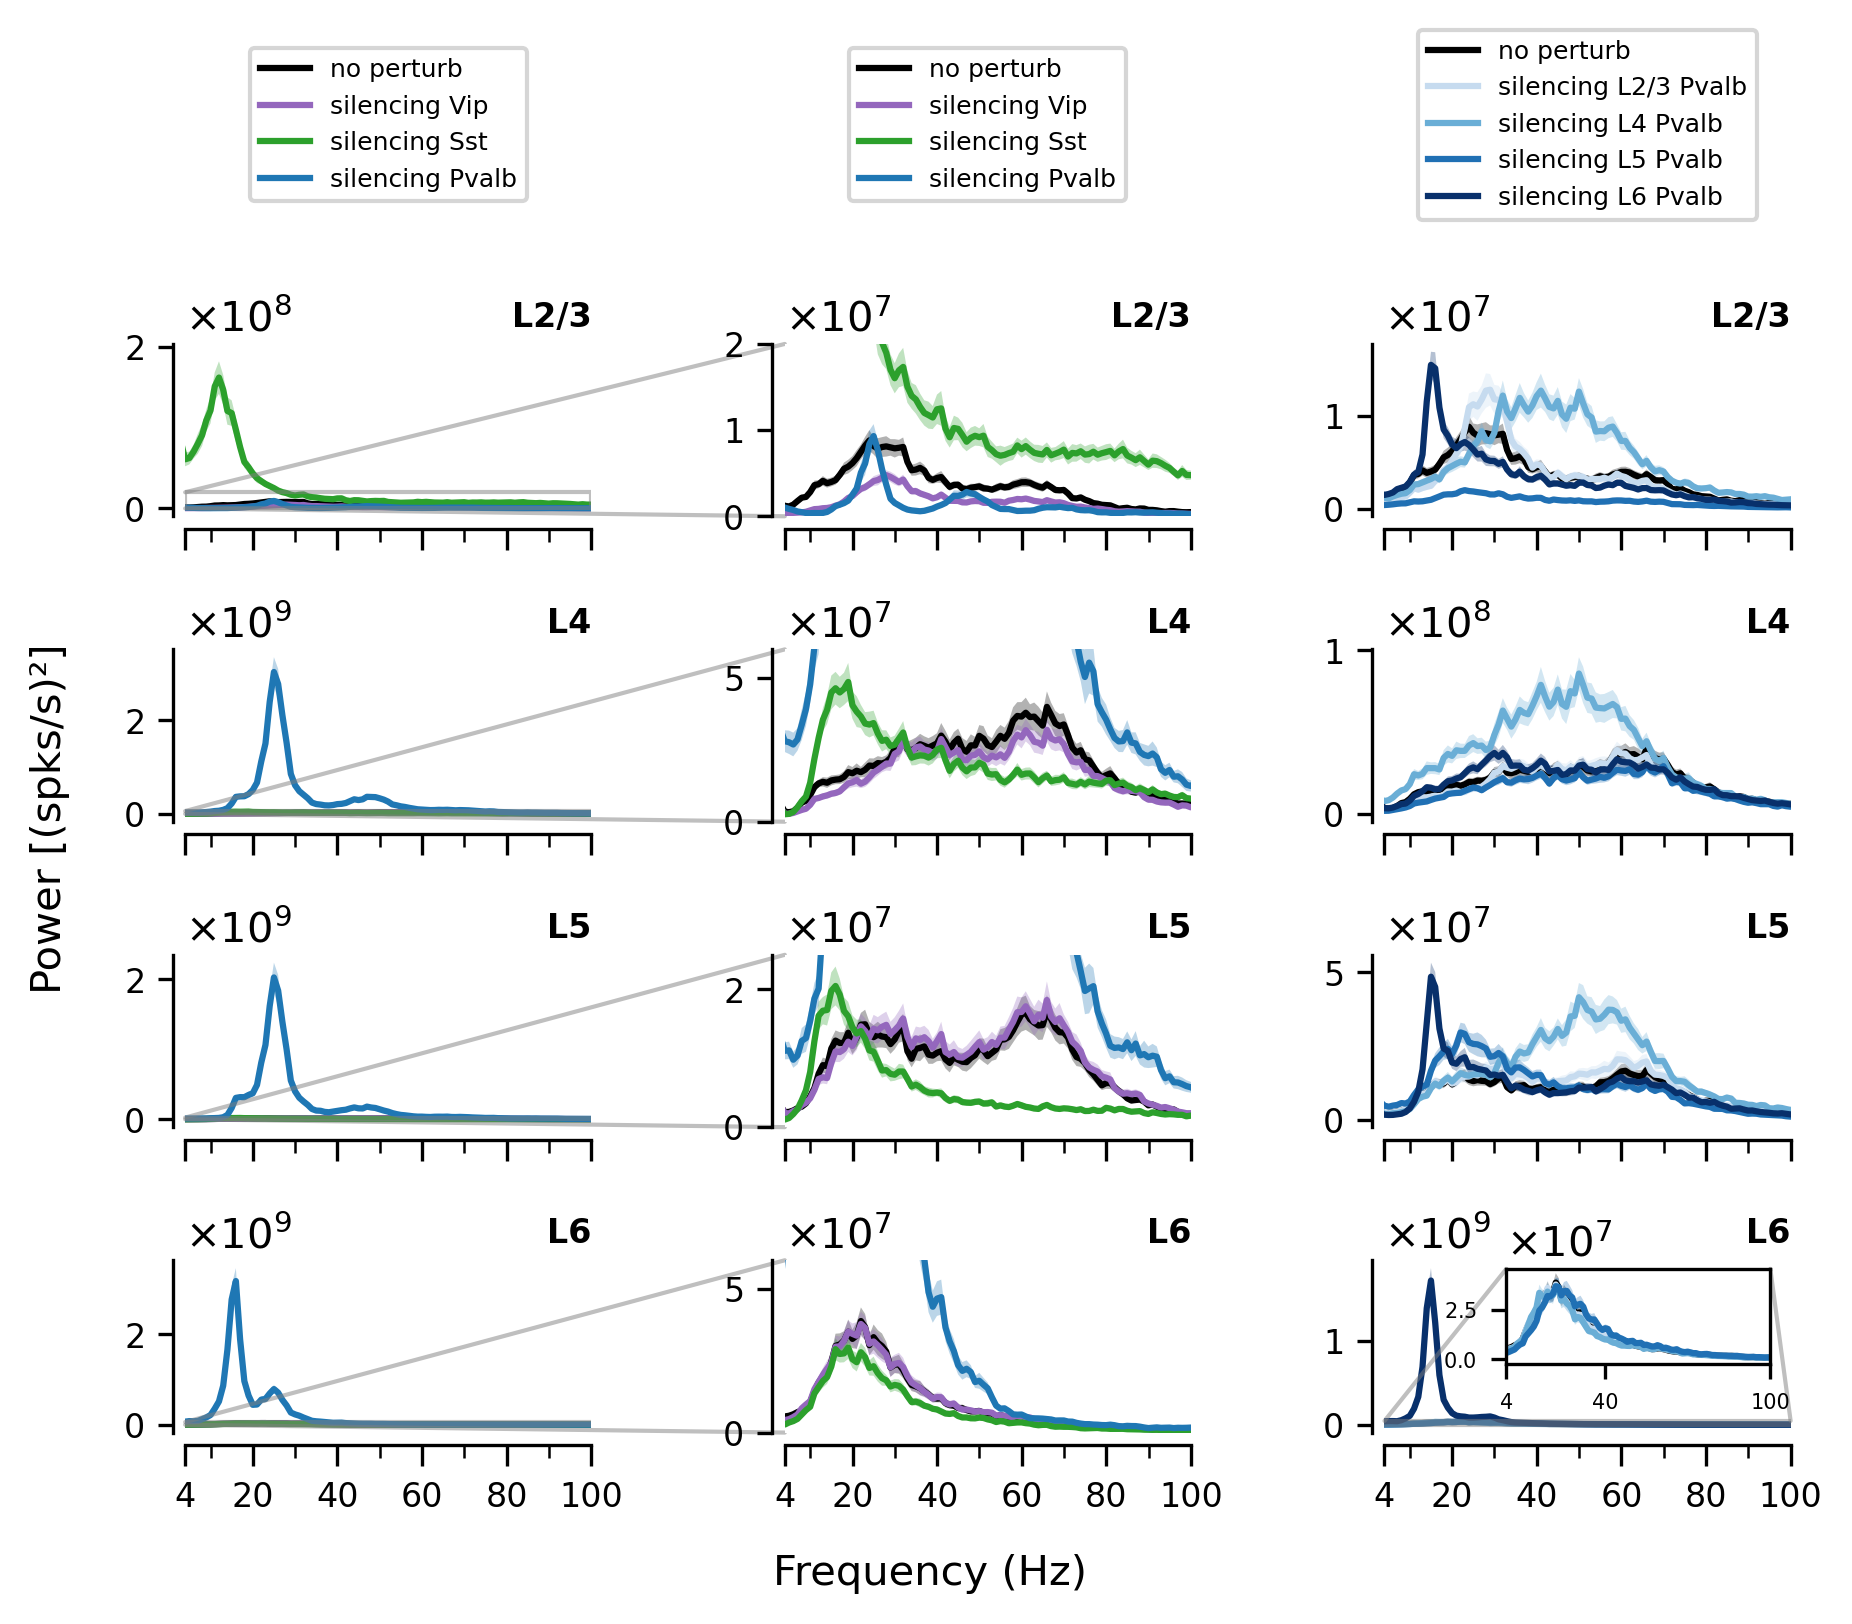

In [8]:
fig, axs = plt.subplots(
    ncols=3, nrows=5, sharex=True, figsize=(6.25, 5.5), dpi=300
)  # , sharey="col"
fig.patch.set_facecolor("none")
f = power_df.loc[0, "f"]

colors = ["tab:purple", "tab:green", "tab:blue"]

jj = 0
axes = axs[:, jj]
ii = 0
ii = plot_func(axes, power_df, list(['no perturb', 'silencing Vip', 'silencing Sst', 'silencing Pvalb']), colors, ii)
# Place legend in the row above (index ii-1, since L2/3 is at ii=0 for layers[1:])
legend_ax = axs[0, jj]  # First row for this column
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axes[0].set_title("Layer by layer\n silencing")
# Hide first row axis
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

jj += 1
axes = axs[:, jj]
ii = 0
ii = plot_func(axes, power_df, list(['no perturb', 'silencing Vip', 'silencing Sst', 'silencing Pvalb']), colors, ii)
# Place legend in the row above (index ii-1, since L2/3 is at ii=0 for layers[1:])
legend_ax = axs[0, jj]  # First row for this column
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# for ax, i in zip(axes[1:], range(1, 6)):
#     ax.set_ylim([0, 4e7])
axs[1, jj].set_ylim([0, 2e7])
axs[2, jj].set_ylim([0, 6e7])
axs[3, jj].set_ylim([0, 2.5e7])
axs[4, jj].set_ylim([0, 6e7])
# axes[0].set_title("Layer by layer\n silencing")
# Hide first row axis
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()
# Add indicate_inset_zoom from col 0 to col 1 (zoom-in panels)
for row in [1, 2, 3, 4]:
    axs[row, jj-1].indicate_inset_zoom(axs[row, jj], edgecolor="gray")

jj += 1
axes = axs[:, jj]
ii = 0
colors = plt.colormaps["Blues"](np.linspace(0, 1, 5))[1:]
ii = plot_func(axes, power_df, list(['no perturb', 'silencing i23Pvalb',
                                     'silencing i4Pvalb', 'silencing i5Pvalb', 'silencing i6Pvalb']), colors, ii)
# Place legend in the row above (index ii-1, since L2/3 is at ii=0 for layers[1:])
legend_ax = axs[0, jj]  # First row for this column
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=['no perturb', 'silencing L2/3 Pvalb', 'silencing L4 Pvalb', 'silencing L5 Pvalb', 'silencing L6 Pvalb'],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axes[0].set_title("Layer by layer\n silencing")
# Hide first row axis
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()
# Inset in panel (col=2, row=4) = axs[4, 2]: zoom in on traces obscured
# by the large amplitude of 'silencing i6Pvalb' at L6
inset_ax = axs[4, jj].inset_axes([0.3, 0.4, 0.65, 0.55])
for cond, c_inset in zip(
    ['no perturb', 'silencing i23Pvalb', 'silencing i4Pvalb', 'silencing i5Pvalb'],
    ['k', colors[0], colors[1], colors[2]]
):
    mean_p = power_df.loc[power_df["condition"].isin([cond]), "mean"]
    se_p = power_df.loc[power_df["condition"].isin([cond]), "se"]
    if not mean_p.empty:
        d = np.vstack(np.asanyarray(mean_p))
        d_se = np.vstack(np.asanyarray(se_p))
        inset_ax.plot(power_df["f"][0], d[4, :], color=c_inset)
        inset_ax.fill_between(
            power_df["f"][0][1:],
            d[4, 1:] - 1.96 * d_se[4, 1:], # 95% confidence interval
            d[4, 1:] + 1.96 * d_se[4, 1:], 
            facecolor=c_inset,
            alpha=0.3,
        )
inset_ax.set_xlim([4, 100])
inset_ax.set_xticks([4, 40, 100])
inset_ax.tick_params(labelsize=5)
formatter_ins = ScalarFormatter(useMathText=True)
formatter_ins.set_powerlimits((-3, 3))
inset_ax.yaxis.set_major_formatter(formatter_ins)
inset_ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 3))
axs[4, jj].indicate_inset_zoom(inset_ax, edgecolor="gray")

fig.supylabel("Power [(spks/s)²]", fontsize=10)
fig.supxlabel("Frequency (Hz)", fontsize=10, y=0.03)
fig.tight_layout()

fig.savefig(
    "paper_figs/fig3_dg_power_inh_pop_silencing_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


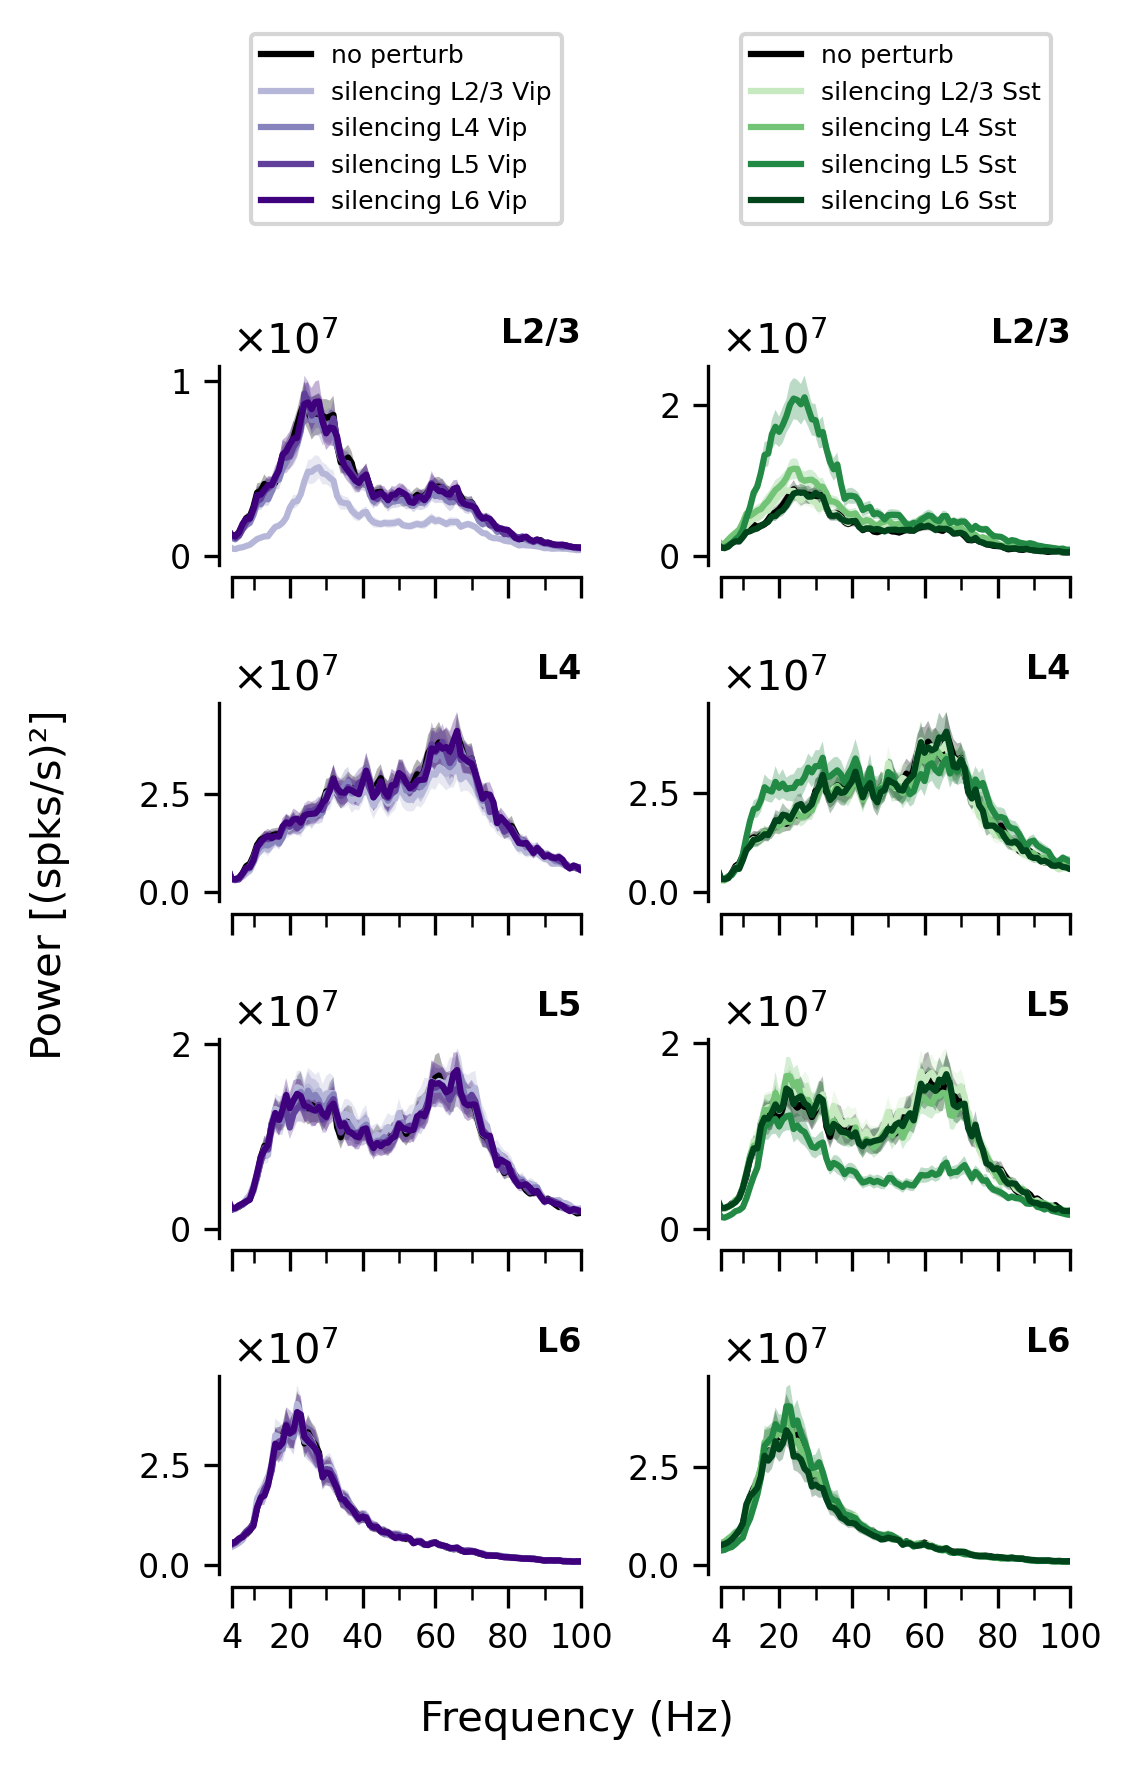

In [9]:
fig, axs = plt.subplots(
    ncols=2, nrows=5, sharex=True, figsize=(3.8, 6), dpi=300
)  # , sharey="col"
fig.patch.set_facecolor("none")
f = power_df.loc[0, "f"]

jj = 0
axes = axs[:, jj]
ii = 0
colors = plt.colormaps["Purples"](np.linspace(0, 1, 6))[2:]
ii = plot_func(axes, power_df, list(['no perturb', 'silencing i23Vip', 
                                     'silencing i4Vip', 'silencing i5Vip', 
                                     'silencing i6Vip']), colors, ii)
# Place legend in the row above (index ii-1, since L2/3 is at ii=0 for layers[1:])
legend_ax = axs[0, jj]  # First row for this column
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=['no perturb', 'silencing L2/3 Vip', 'silencing L4 Vip', 'silencing L5 Vip', 'silencing L6 Vip'],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axes[0].set_title("Layer by layer\n silencing")
# Hide first row axis
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

jj += 1
axes = axs[:, jj]
ii = 0
colors = plt.colormaps["Greens"](np.linspace(0, 1, 5))[1:]
ii = plot_func(axes, power_df, list(['no perturb', 'silencing i23Sst', 
                                     'silencing i4Sst', 'silencing i5Sst', 'silencing i6Sst']), colors, ii)
# Place legend in the row above (index ii-1, since L2/3 is at ii=0 for layers[1:])
legend_ax = axs[0, jj]  # First row for this column
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=['no perturb', 'silencing L2/3 Sst', 'silencing L4 Sst', 'silencing L5 Sst', 'silencing L6 Sst'],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axes[0].set_title("Silencing of layer\n combinations")
# Hide first row axis
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

fig.supylabel("Power [(spks/s)²]", fontsize=10)
fig.supxlabel("Frequency (Hz)", y = 0.025, fontsize=10)
fig.tight_layout()

fig.savefig(
    "paper_figs/fig3_dg_power_inh_pop_silencing_suppl_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)
